<a href="https://colab.research.google.com/github/afridajahan/periocular-deepfake-detection/blob/main/roi_extraction_efficientnetb0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Cell 1: Install deps
!pip install mediapipe imagehash -q

# Cell 2: Imports
from google.colab import drive

try:
    drive.mount('/content/drive')
except ValueError:
    # Already mounted - this is fine, just continue
    print("ℹ️ Drive already mounted, continuing...")

import cv2
import mediapipe as mp
import numpy as np
import os
import shutil
import zipfile
import csv
from tqdm import tqdm
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from PIL import Image
import imagehash

print("✅ Setup complete!")


# Cell 3: ROI Extractor
class PeriocularROIExtractor:
    LEFT_EYE = [33, 7, 163, 144, 145, 153, 154, 155, 133, 173, 157, 158, 159, 160, 161, 246]
    RIGHT_EYE = [362, 382, 381, 380, 374, 373, 390, 249, 263, 466, 388, 387, 386, 385, 384, 398]
    ALL_PERIOCULAR = LEFT_EYE + RIGHT_EYE

    LEFT_INNER_IDX = LEFT_EYE.index(133)
    RIGHT_INNER_IDX = len(LEFT_EYE) + RIGHT_EYE.index(263)

    def __init__(self, target_h, target_w, padding_ratio=0.35, align=True,
                 target_aspect=2.0, interpolation=cv2.INTER_LANCZOS4):
        self.target_h = target_h
        self.target_w = target_w
        self.padding_ratio = padding_ratio
        self.align = align
        self.target_aspect = target_aspect
        self.interpolation = interpolation
        self.face_landmarker = None
        self._initialize_landmarker()

    def _initialize_landmarker(self):
        model_path = 'face_landmarker_v2_with_blendshapes.task'
        if not os.path.exists(model_path):
            print("📥 Downloading MediaPipe model...")
            import urllib.request
            url = "https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task"
            urllib.request.urlretrieve(url, model_path)
            print("✅ Model downloaded!")

        base_options = python.BaseOptions(model_asset_path=model_path)
        options = vision.FaceLandmarkerOptions(
            base_options=base_options,
            running_mode=vision.RunningMode.IMAGE,
            num_faces=1
        )
        self.face_landmarker = vision.FaceLandmarker.create_from_options(options)
        print("✅ Face Landmarker ready!")

    def _fixed_aspect_box(self, x1, y1, x2, y2, w, h, target_aspect):
        box_w = x2 - x1
        box_h = y2 - y1
        current_aspect = box_w / box_h if box_h > 0 else target_aspect

        cx = (x1 + x2) / 2.0
        cy = (y1 + y2) / 2.0

        if current_aspect > target_aspect:
            new_w = box_w
            new_h = box_w / target_aspect
        else:
            new_h = box_h
            new_w = box_h * target_aspect

        nx1 = cx - new_w / 2.0
        nx2 = cx + new_w / 2.0
        ny1 = cy - new_h / 2.0
        ny2 = cy + new_h / 2.0

        if nx1 < 0:
            nx2 -= nx1
            nx1 = 0
        if ny1 < 0:
            ny2 -= ny1
            ny1 = 0
        if nx2 > w:
            nx1 -= (nx2 - w)
            nx2 = w
        if ny2 > h:
            ny1 -= (ny2 - h)
            ny2 = h

        nx1 = int(max(0, round(nx1)))
        ny1 = int(max(0, round(ny1)))
        nx2 = int(min(w, round(nx2)))
        ny2 = int(min(h, round(ny2)))
        return nx1, ny1, nx2, ny2

    def _resize_to_fixed_rect(self, img):
        return cv2.resize(img, (self.target_w, self.target_h), interpolation=self.interpolation)

    def extract_roi_from_image(self, image_path):
        image = cv2.imread(image_path)
        if image is None:
            return None, "unreadable_file"

        h, w = image.shape[:2]

        try:
            rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
            result = self.face_landmarker.detect(mp_image)
        except Exception as e:
            return None, f"mediapipe_error:{type(e).__name__}"

        if not result.face_landmarks:
            return None, "no_face_detected"

        landmarks = result.face_landmarks[0]
        pts = np.array([(landmarks[idx].x * w, landmarks[idx].y * h)
                         for idx in self.ALL_PERIOCULAR], dtype=np.float32)

        left_inner = pts[self.LEFT_INNER_IDX]
        right_inner = pts[self.RIGHT_INNER_IDX]
        eye_dist = np.linalg.norm(right_inner - left_inner)
        if eye_dist < 1e-3:
            return None, "degenerate_eye_distance"

        working_image = image
        working_pts = pts

        if self.align:
            dy = right_inner[1] - left_inner[1]
            dx = right_inner[0] - left_inner[0]
            angle = np.degrees(np.arctan2(dy, dx))
            center = ((left_inner[0] + right_inner[0]) / 2.0,
                      (left_inner[1] + right_inner[1]) / 2.0)
            rot_mat = cv2.getRotationMatrix2D(center, angle, 1.0)
            working_image = cv2.warpAffine(image, rot_mat, (w, h),
                                            flags=cv2.INTER_LINEAR,
                                            borderMode=cv2.BORDER_REPLICATE)
            ones = np.ones((pts.shape[0], 1), dtype=np.float32)
            pts_h = np.hstack([pts, ones])
            working_pts = (rot_mat @ pts_h.T).T

        padding = eye_dist * self.padding_ratio
        x1 = working_pts[:, 0].min() - padding
        y1 = working_pts[:, 1].min() - padding
        x2 = working_pts[:, 0].max() + padding
        y2 = working_pts[:, 1].max() + padding

        x1, y1, x2, y2 = self._fixed_aspect_box(x1, y1, x2, y2, w, h, self.target_aspect)

        roi = working_image[y1:y2, x1:x2]
        if roi.size == 0 or roi.shape[0] < 40 or roi.shape[1] < 40:
            return None, "roi_too_small"

        roi_resized = self._resize_to_fixed_rect(roi)
        return roi_resized, "ok"


# Cell 4: Set paths + run extraction across train/test/validate
print("\n" + "="*60)
print("🚀 PERIOCULAR ROI EXTRACTOR (FIXED RECTANGULAR SIZE - EfficientNetB0)")
print("="*60)

DATASET_ZIP = '/content/drive/MyDrive/real_ai_dataset.zip'
OUTPUT_NAME = 'roi_FDataset_rect_112x224'
TARGET_H = 112
TARGET_W = 224
TARGET_ASPECT = TARGET_W / TARGET_H
PADDING_RATIO = 0.35
ALIGN_FACES = True
RESIZE_INTERPOLATION = cv2.INTER_LANCZOS4
SPLITS = ['train', 'test', 'validate']

if not os.path.exists(DATASET_ZIP):
    print(f"❌ Dataset not found at: {DATASET_ZIP}")
    os.system("ls -lh /content/drive/MyDrive/ | grep -E '\\.zip'")
    raise FileNotFoundError(f"Dataset zip not found at {DATASET_ZIP}")

print(f"✅ Found dataset: {DATASET_ZIP}")

print("\n📦 Extracting ZIP...")
extract_path = '/content/dataset'
with zipfile.ZipFile(DATASET_ZIP, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

def find_dataset_root(base_path, splits):
    for root, dirs, files in os.walk(base_path):
        if all(s in dirs for s in splits):
            return root
    return None

dataset_root = find_dataset_root(extract_path, SPLITS)
if not dataset_root:
    raise FileNotFoundError(f"Could not find folders {SPLITS} inside the zip")

print(f"✅ Found dataset root: {dataset_root}")

split_paths = {}
for split in SPLITS:
    split_dir = os.path.join(dataset_root, split)
    real_path = os.path.join(split_dir, '0')
    fake_path = os.path.join(split_dir, '1')
    if not (os.path.isdir(real_path) and os.path.isdir(fake_path)):
        raise FileNotFoundError(f"Missing 0/ or 1/ inside {split_dir}")
    split_paths[split] = (real_path, fake_path)
    print(f"✅ {split}: real={real_path}  fake={fake_path}")

OUTPUT_BASE = f'/content/{OUTPUT_NAME}'

extractor = PeriocularROIExtractor(target_h=TARGET_H, target_w=TARGET_W,
                                    padding_ratio=PADDING_RATIO,
                                    align=ALIGN_FACES,
                                    target_aspect=TARGET_ASPECT,
                                    interpolation=RESIZE_INTERPOLATION)

failure_log_path = f'/content/drive/MyDrive/{OUTPUT_NAME}_failures.csv'
manifest_path = f'/content/drive/MyDrive/{OUTPUT_NAME}_manifest.csv'
failure_rows = []
manifest_rows = []


def process_folder(input_dir, output_dir, split_name, label_name, subtype_name):
    files = [f for f in os.listdir(input_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    success = 0
    status_counts = {}
    for img_file in tqdm(files, desc=f"{split_name}/{label_name}/{subtype_name}"):
        img_path = os.path.join(input_dir, img_file)
        roi, status = extractor.extract_roi_from_image(img_path)
        status_counts[status] = status_counts.get(status, 0) + 1
        if roi is not None:
            name = os.path.splitext(img_file)[0]
            out_name = f"{split_name}_{subtype_name}_{name}_roi.jpg"
            out_path = os.path.join(output_dir, out_name)
            cv2.imwrite(out_path, roi)
            phash = str(imagehash.phash(Image.open(out_path)))
            manifest_rows.append([split_name, label_name, subtype_name, out_name, phash])
            success += 1
        else:
            failure_rows.append([split_name, label_name, subtype_name, img_file, status])
    return len(files), success, status_counts


summary = {}
for split, (real_path, fake_path) in split_paths.items():
    output_real = os.path.join(OUTPUT_BASE, split, 'real')
    output_fake = os.path.join(OUTPUT_BASE, split, 'fake')
    os.makedirs(output_real, exist_ok=True)
    os.makedirs(output_fake, exist_ok=True)

    print(f"\n📁 Processing split: {split}")
    real_total, real_success, real_status = process_folder(real_path, output_real, split, 'real', 'real')
    print(f"✅ {split}/REAL: {real_success}/{real_total} ({real_success/real_total*100:.1f}%)")
    print(f"   Breakdown: {real_status}")

    fake_total, fake_success, fake_status = process_folder(fake_path, output_fake, split, 'fake', 'mixed')
    print(f"✅ {split}/FAKE: {fake_success}/{fake_total} ({fake_success/fake_total*100:.1f}%)")
    print(f"   Breakdown: {fake_status}")

    real_rate = real_success / real_total * 100 if real_total else 0
    fake_rate = fake_success / fake_total * 100 if fake_total else 0
    rate_gap = abs(real_rate - fake_rate)
    print(f"📊 [{split}] Extraction rate gap (real vs fake): {rate_gap:.1f} pp")
    if rate_gap > 3.0:
        print(f"⚠️  WARNING: [{split}] real vs fake extraction rates differ by more than 3pp.")
    else:
        print(f"✅ [{split}] Extraction rates are close between classes.")

    summary[split] = {
        'real_total': real_total, 'real_success': real_success,
        'fake_total': fake_total, 'fake_success': fake_success
    }

hash_to_group = {}
for row in manifest_rows:
    phash = row[4]
    if phash not in hash_to_group:
        hash_to_group[phash] = len(hash_to_group)
for row in manifest_rows:
    row.append(hash_to_group[row[4]])

n_groups = len(hash_to_group)
n_images = len(manifest_rows)
print(f"\n📊 Near-duplicate check: {n_images} images -> {n_groups} distinct hash groups")
if n_images - n_groups > 0:
    print(f"   {n_images - n_groups} images share a perceptual hash with another image.")
    dupe_splits = {(r[0], r[1]) for r in manifest_rows if
                   [row[4] for row in manifest_rows].count(r[4]) > 1}

    from collections import defaultdict
    group_splits = defaultdict(set)
    for row in manifest_rows:
        group_splits[row[5]].add(row[0])
    leaking_groups = {g: s for g, s in group_splits.items() if len(s) > 1}
    if leaking_groups:
        print(f"⚠️  WARNING: {len(leaking_groups)} near-duplicate group(s) span multiple splits "
              f"(possible train/test/validate leakage)!")
    else:
        print("✅ No cross-split near-duplicate leakage detected.")

with open(manifest_path, 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['split', 'label', 'subtype', 'filename', 'phash', 'group_id'])
    writer.writerows(manifest_rows)
print(f"\n📝 Manifest saved: {manifest_path}")

with open(failure_log_path, 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['split', 'label', 'subtype', 'filename', 'failure_reason'])
    writer.writerows(failure_rows)
print(f"📝 Failure manifest saved: {failure_log_path}")

total = sum(s['real_success'] + s['fake_success'] for s in summary.values())
print(f"\n📊 Total ROIs across all splits: {total}")

print("\n💾 Saving to Google Drive...")
drive_zip = f'/content/drive/MyDrive/{OUTPUT_NAME}'
shutil.make_archive(drive_zip, 'zip', OUTPUT_BASE)

size_mb = os.path.getsize(f"{drive_zip}.zip") / (1024**2)
print(f"\n✅ Saved: {drive_zip}.zip ({size_mb:.2f} MB)")

shutil.rmtree(OUTPUT_BASE)
shutil.rmtree(extract_path)

print("\n" + "="*60)
print("🎉 COMPLETE!")
print("="*60)
print(f"\n📁 /content/drive/MyDrive/{OUTPUT_NAME}.zip")
for split, s in summary.items():
    print(f"   ├── {split}/")
    print(f"   │     ├── real/  ({s['real_success']} images)")
    print(f"   │     └── fake/  ({s['fake_success']} images)")
print(f"📝 Review skipped images in: {OUTPUT_NAME}_failures.csv")



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 71.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 19.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 10.0 MB/s eta 0:00:00
Mounted at /content/drive
✅ Setup complete!

🚀 PERIOCULAR ROI EXTRACTOR (FIXED RECTANGULAR SIZE - EfficientNetB0)
✅ Found dataset: /content/drive/MyDrive/real_ai_dataset.zip

📦 Extracting ZIP...
✅ Found dataset root: /content/dataset/dataset
✅ train: real=/content/dataset/dataset/train/0  fake=/content/dataset/dataset/train/1
✅ test: real=/content/dataset/dataset/test/0  fake=/content/dataset/dataset/test/1
✅ validate: real=/content/dataset/dataset/validate/0  fake=/content/dataset/dataset/validate/1
📥 Downloading MediaPipe model...
✅ Model downloaded!
✅ Face Landmarker ready!

📁 Processing split: train


train/real/real: 100%|██████████| 42000/42000 [22:03<00:00, 31.72it/s]


✅ train/REAL: 41954/42000 (99.9%)
   Breakdown: {'ok': 41954, 'roi_too_small': 4, 'no_face_detected': 42}


train/fake/mixed: 100%|██████████| 30574/30574 [15:59<00:00, 31.88it/s]


✅ train/FAKE: 30565/30574 (100.0%)
   Breakdown: {'ok': 30565, 'roi_too_small': 3, 'no_face_detected': 6}
📊 [train] Extraction rate gap (real vs fake): 0.1 pp
✅ [train] Extraction rates are close between classes.

📁 Processing split: test


...

✅ test/FAKE: 10187/10190 (100.0%)
   Breakdown: {'ok': 10187, 'roi_too_small': 1, 'no_face_detected': 2}
📊 [test] Extraction rate gap (real vs fake): 0.0 pp
✅ [test] Extraction rates are close between classes.

📁 Processing split: validate


validate/real/real: 100%|██████████| 14000/14000 [07:17<00:00, 32.00it/s]


✅ validate/REAL: 13979/14000 (99.9%)
   Breakdown: {'ok': 13979, 'no_face_detected': 19, 'roi_too_small': 2}


validate/fake/mixed: 100%|██████████| 10190/10190 [05:22<00:00, 31.62it/s]


✅ validate/FAKE: 10189/10190 (100.0%)
   Breakdown: {'ok': 10189, 'roi_too_small': 1}
📊 [validate] Extraction rate gap (real vs fake): 0.1 pp
✅ [validate] Extraction rates are close between classes.

📊 Near-duplicate check: 120863 images -> 120807 distinct hash groups
   56 images share a perceptual hash with another image.
⚠️  WARNING: 32 near-duplicate group(s) span multiple splits (possible train/test/validate leakage)!

📝 Manifest saved: /content/drive/MyDrive/roi_FDataset_rect_112x224_manifest.csv
📝 Failure manifest saved: /content/drive/MyDrive/roi_FDataset_rect_112x224_failures.csv

📊 Total ROIs across all splits: 120863

💾 Saving to Google Drive...

✅ Saved: /content/drive/MyDrive/roi_FDataset_rect_112x224.zip (995.71 MB)

🎉 COMPLETE!

📁 /content/drive/MyDrive/roi_FDataset_rect_112x224.zip
   ├── train/
   │     ├── real/  (41954 images)
   │     └── fake/  (30565 images)
   ├── test/
   │     ├── real/  (13989 images)
   │     └── fake/  (10187 images)
   ├── validate/
   │   

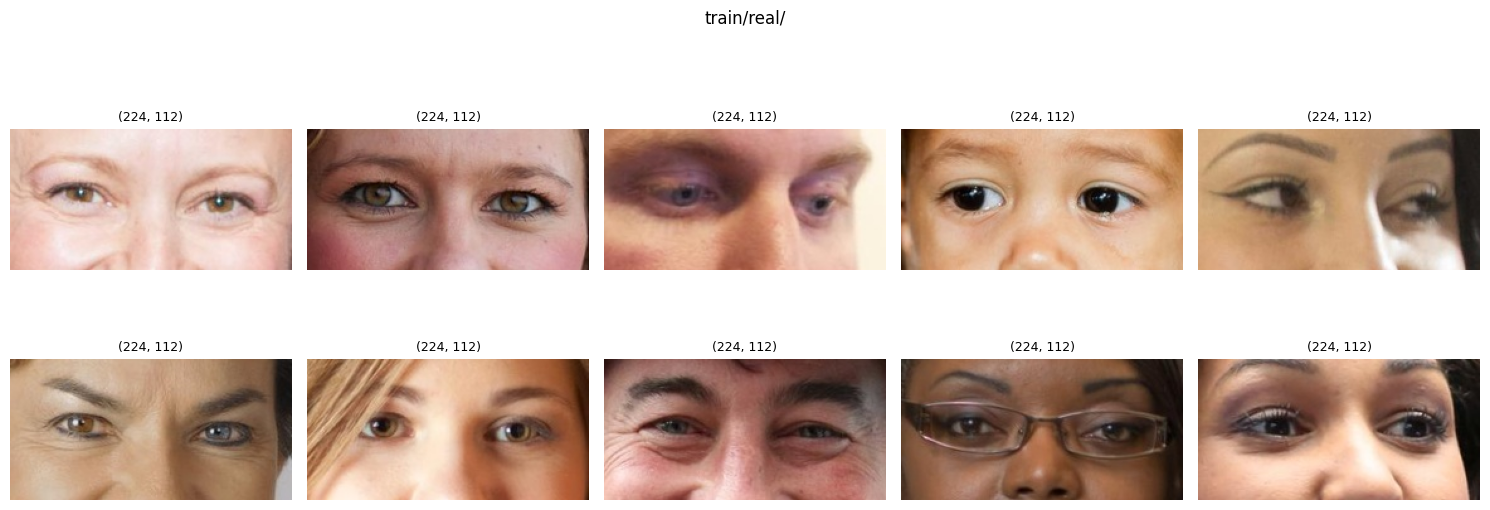

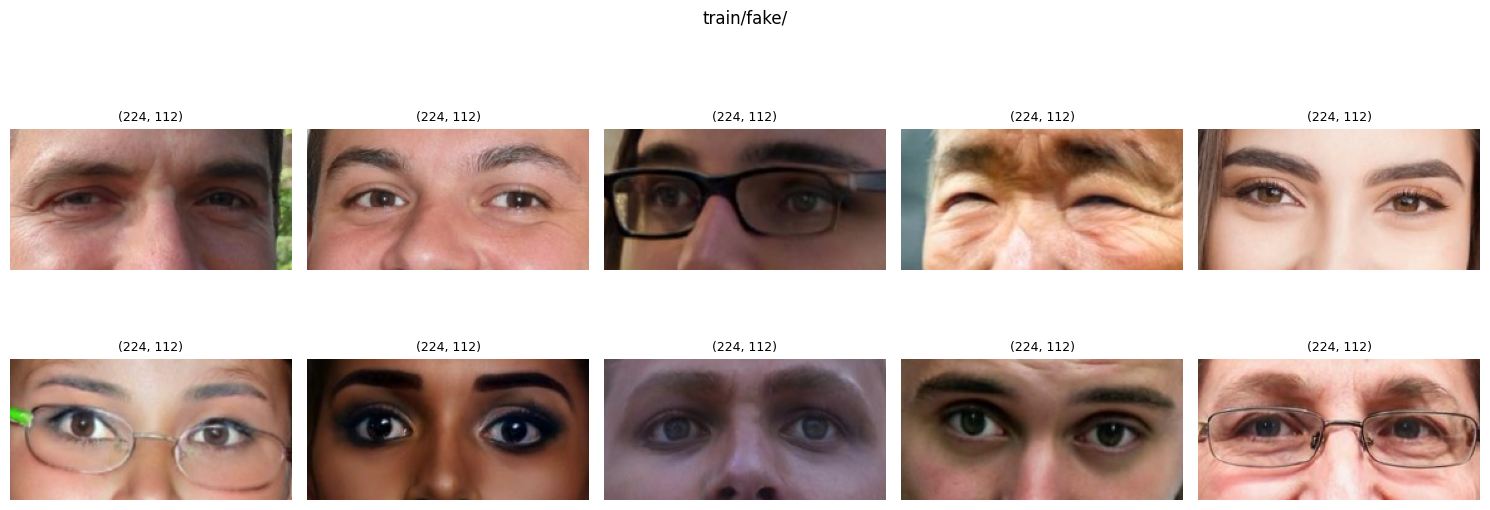

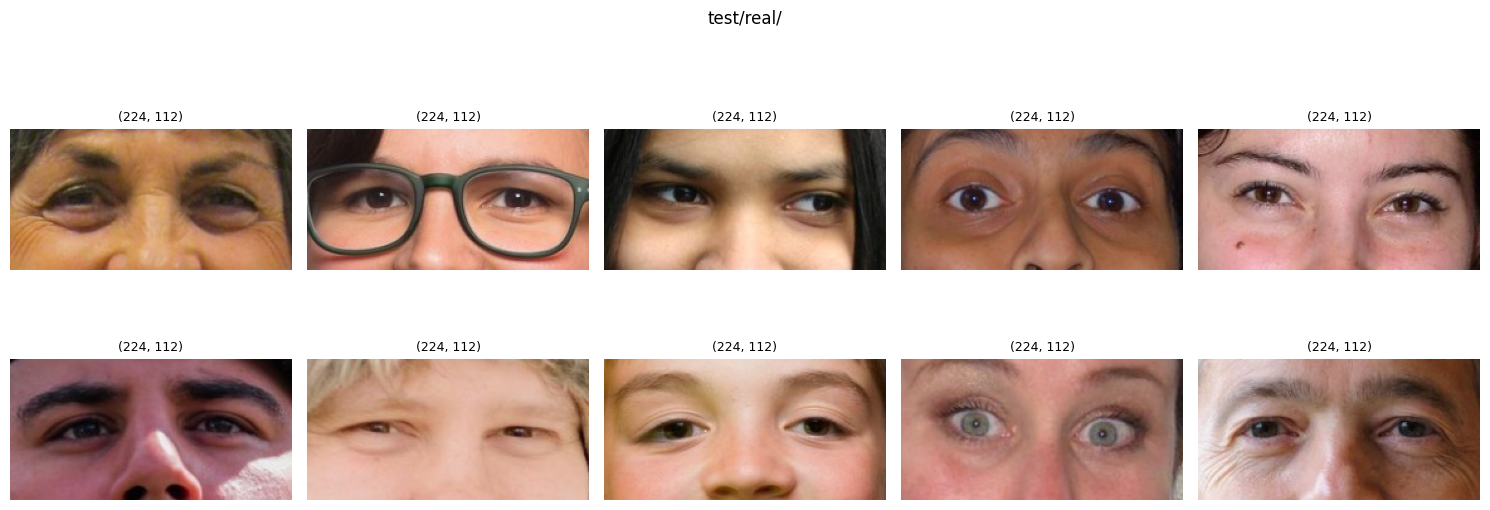

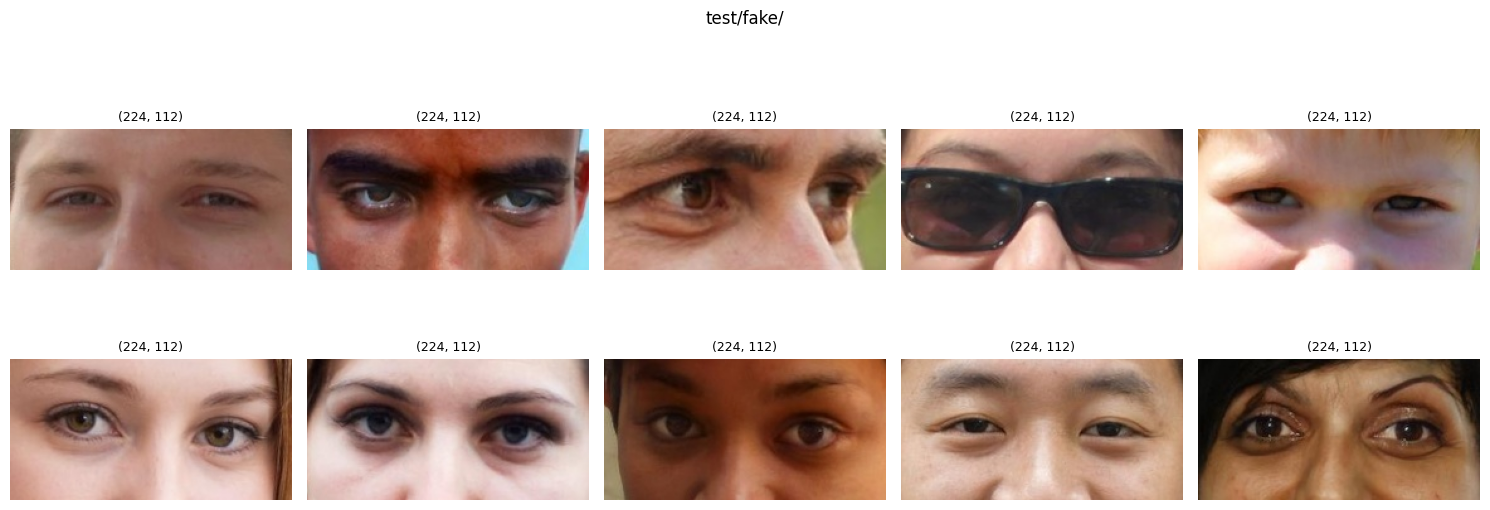

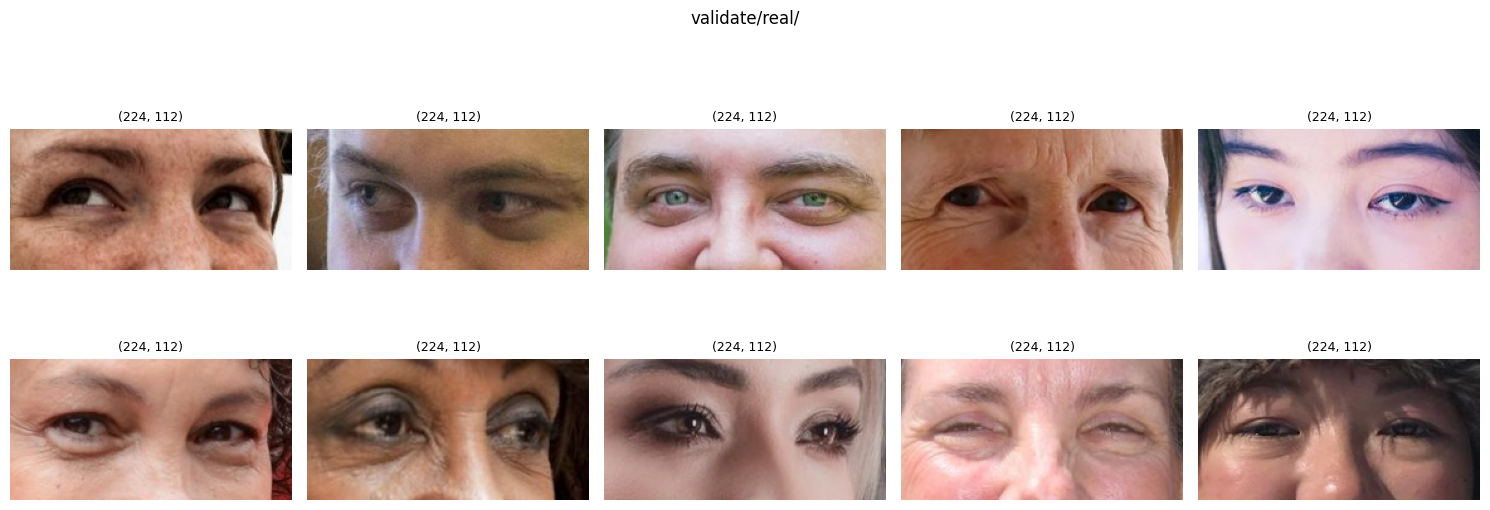

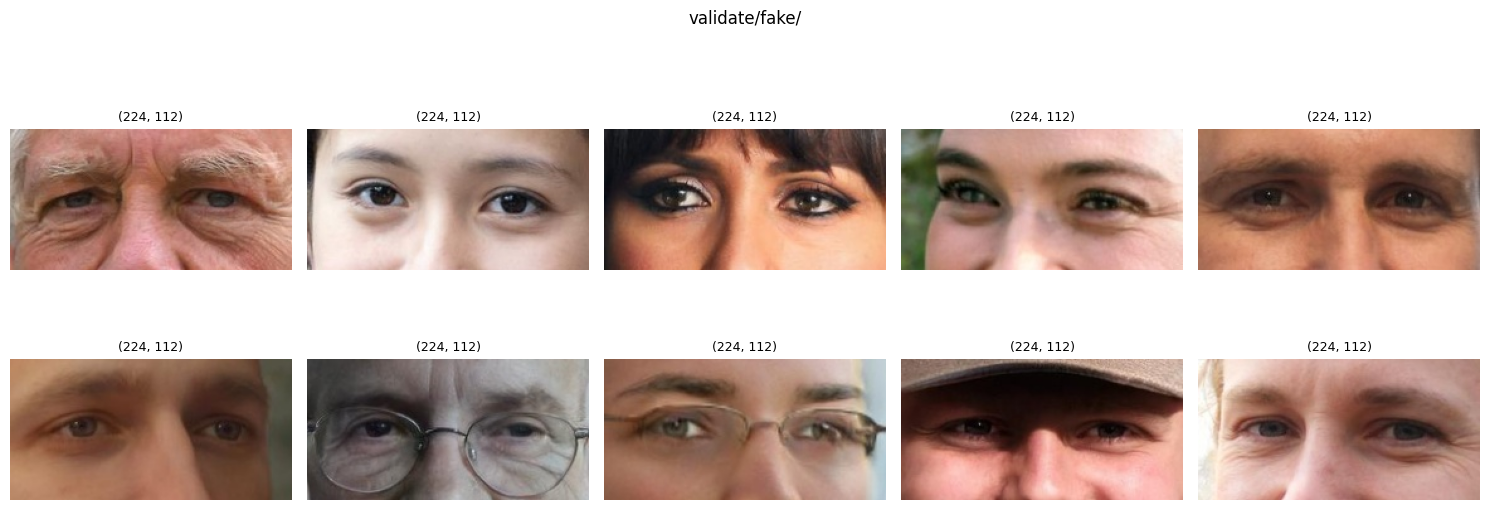

In [ ]:
# Just to check if images are extracted properly
import zipfile, random
from PIL import Image
import matplotlib.pyplot as plt

def preview_from_zip(zip_path, folder_prefix, n=10, seed=1):
    with zipfile.ZipFile(zip_path, 'r') as z:
        names = [f for f in z.namelist() if f.startswith(folder_prefix) and f.lower().endswith('.jpg')]
        if not names:
            print(f"⚠️ No images found with prefix '{folder_prefix}' — check the path inside the zip.")
            return
        sample = random.Random(seed).sample(names, min(n, len(names)))
        fig, axes = plt.subplots(2, 5, figsize=(15, 6))
        for ax, name in zip(axes.flat, sample):
            with z.open(name) as f:
                img = Image.open(f).convert('RGB')
                ax.imshow(img)
                ax.set_title(f"{img.size}", fontsize=9)
                ax.axis('off')
        plt.suptitle(folder_prefix)
        plt.tight_layout()
        plt.show()

ZIP = '/content/drive/MyDrive/roi_FDataset_rect_112x224.zip'

# Preview each split separately
for split in ['train', 'test', 'validate']:
    preview_from_zip(ZIP, f'{split}/real/', n=10)
    preview_from_zip(ZIP, f'{split}/fake/', n=10)